# Decode real LLRs at any bound, on a CPU

This notebook runs the bounded receiver from the paper on real data, with the real 5G NR LDPC decoder, on an ordinary CPU.

$$L_{\mathrm{R5}} = L_{\mathrm{c}} + \mathrm{clip}\left(L_{\mathrm{R3}} - L_{\mathrm{c}},\ \pm\Delta_{\max}\right)$$

$L_{\mathrm{c}}$ is the classical receiver's log-likelihood ratio (LLR) for a coded bit, $L_{\mathrm{R3}}$ the trained network's,
and $L_{\mathrm{R5}}$ the bounded output that goes to the decoder. You will:

1. load two small samples of stored LLRs from the paper's measurement campaign;
2. check that $\Delta_{\max} = 0$ gives back the classical receiver's LLRs bit for bit, whatever the network says;
3. decode the samples at the paper's six bounds and confirm the result matches the recorded decode, block for block;
4. decode them at any bound you like;
5. put your own receiver's LLRs through the bound.

Setup: `pip install -r notebook/requirements.txt` in a Python 3.10 environment, then open this notebook from the repository
(see the README). No GPU is needed. The interactive page with the full results is at
<https://m7mdal7aj.github.io/bounded-neural-receiver/>.

In [1]:
import os
os.environ.setdefault("TF_USE_LEGACY_KERAS", "1")    # Sionna 1.2.2 uses the Keras 2 API
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")    # CPU only: the decoder needs no GPU
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # keep TensorFlow's start-up messages out of the way

import json, math, sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

REPO = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA = REPO / "notebook" / "data"
sys.path.insert(0, str(REPO / "receiver"))
assert (DATA / "training_snr19.npz").exists(), "open this notebook from the repository (its notebook/ folder or the root)"

# the page's colours: classical, network alone, bounded
BROWN, GREEN, RED = "#7c2d12", "#059669", "#e00800"

## 1. The samples

Each sample is the first blocks (transport blocks, one per slot) of one point of the paper's seed-42 sweep, stored exactly as
the measurement wrote them: the classical LLRs, the network's LLRs, and the true information bits. One sample is from the
condition the network was trained on; the other from a harsher IQ imbalance it never saw.

In [2]:
def load_sample(name):
    meta = json.loads((DATA / f"{name}.json").read_text())
    z = np.load(DATA / f"{name}.npz")
    bits = np.unpackbits(z["info_bits"], axis=-1)[:, :meta["k_info_bits"]]
    return meta, z["llr_classical"], z["llr_network"], bits

SAMPLES = {name: load_sample(name) for name in ("training_snr19", "harsher_iq_snr20")}
for name, (meta, lc, ln, bits) in SAMPLES.items():
    print(f"{meta['label']}: CDL-{meta['channel']} channel, IRR {meta['eval_irr_db']:g} dB, Eb/N0 {meta['snr_db']:g} dB")
    print(f"   {meta['source']}")
    print(f"   {lc.shape[0]} blocks x {lc.shape[1]:,} coded bits, {bits.shape[1]:,} information bits per block; "
          f"MCS {meta['mcs']}, {meta['n_prb']} resource blocks, {meta['n_rx_ant']} receive antennas")

cfg = json.loads((REPO / "results" / "run_config.json").read_text())
print(f"\nFor scale: each point on the page uses {cfg['blocks_per_point']:,} blocks for each of {len(cfg['seeds'])} seeds.")
print("Sign convention:", SAMPLES["training_snr19"][0]["llr_sign"])

Training conditions: CDL-C channel, IRR 25 dB, Eb/N0 19 dB
   the first 24 of 1920 blocks of the seed-42 sweep at 19 dB
   24 blocks x 58,752 coded bits, 54,296 information bits per block; MCS 27, 51 resource blocks, 2 receive antennas
Harsher IQ imbalance: CDL-C channel, IRR 20 dB, Eb/N0 20 dB
   the first 24 of 1920 blocks of the seed-42 sweep at 20 dB
   24 blocks x 58,752 coded bits, 54,296 information bits per block; MCS 27, 51 resource blocks, 2 receive antennas

For scale: each point on the page uses 1,920 blocks for each of 3 seeds.
Sign convention: positive LLR means bit value 1: L = log P(b=1)/P(b=0)


## 2. The bound

The function below is the bound with the same arithmetic the measurement used, $\mathrm{clip}(L_{\mathrm{R3}},\ L_{\mathrm{c}} - \Delta_{\max},\ L_{\mathrm{c}} + \Delta_{\max})$,
which equals the formula above. At $\Delta_{\max} = 0$ it returns $L_{\mathrm{c}}$ exactly; as $\Delta_{\max} \to \infty$ it returns $L_{\mathrm{R3}}$.

In [3]:
def bound(l_classical, l_network, dmax):
    "The bounded receiver's LLRs: each bit moved at most dmax away from the classical LLR, towards the network's."
    l_classical = np.asarray(l_classical, dtype=np.float32)
    l_network = np.asarray(l_network, dtype=np.float32)
    if l_classical.shape != l_network.shape:
        raise ValueError(f"shapes differ: {l_classical.shape} and {l_network.shape}")
    if dmax < 0:
        raise ValueError("dmax must be zero or positive")
    if dmax == 0:
        return l_classical.copy()
    if math.isinf(dmax):
        return l_network.copy()
    d = np.float32(dmax)
    return np.clip(l_network, l_classical - d, l_classical + d)

DMAX = {"0": 0.0, "ln2": math.log(2), "ln4": math.log(4), "ln8": math.log(8), "ln16": math.log(16), "unbounded": math.inf}
LABEL = {"0": "classical (Δmax = 0)", "ln2": "Δmax = ln 2", "ln4": "Δmax = ln 4", "ln8": "Δmax = ln 8",
         "ln16": "Δmax = ln 16", "unbounded": "network alone (Δmax = ∞)"}

### Exact classical fallback

$\Delta_{\max} = 0$ returns the classical LLRs bit for bit, whatever the network outputs. Below the network is replaced by random
numbers of any size, and the output is still the classical receiver's, byte for byte.

In [4]:
meta, lc, ln, bits = SAMPLES["training_snr19"]
same = lambda x, y: x.dtype == y.dtype and x.shape == y.shape and x.tobytes() == y.tobytes()

print("Δmax = 0 gives the classical LLRs, byte for byte:   ", same(bound(lc, ln, 0), lc))
print("Δmax = ∞ gives the network's LLRs, byte for byte:   ", same(bound(lc, ln, math.inf), ln))
junk = np.random.default_rng(0).normal(0, 1e4, size=lc.shape).astype(np.float32)
print("Δmax = 0 with a random 'network' instead:           ", same(bound(lc, junk, 0), lc))

Δmax = 0 gives the classical LLRs, byte for byte:    True
Δmax = ∞ gives the network's LLRs, byte for byte:    True
Δmax = 0 with a random 'network' instead:            True


### How far a bit can move

For every other bound, no bit moves further than $\Delta_{\max}$ from the classical LLR. In 32-bit floating point the edge
$L_{\mathrm{c}} \pm \Delta_{\max}$ is itself rounded, so the measured move can exceed $\Delta_{\max}$ by a rounding step; the
last column shows that excess next to the spacing of 32-bit numbers at the largest classical LLR.

In [5]:
spacing = np.spacing(np.float32(np.abs(lc).max()))
print(f"{'bound':<26}{'largest move':>14}{'excess over Δmax':>18}{'share of bits clipped':>24}")
for k in ("ln2", "ln4", "ln8", "ln16"):
    out = bound(lc, ln, DMAX[k])
    move = np.abs(out - lc).max()
    clipped = np.mean(np.abs(ln - lc) > DMAX[k])
    print(f"{LABEL[k]:<26}{move:>14.6f}{move - np.float32(DMAX[k]):>18.1e}{clipped:>23.1%}")
print(f"\nSpacing of 32-bit numbers at the largest |Lc| in this sample ({np.abs(lc).max():,.1f}): {spacing:.1e}")

bound                       largest move  excess over Δmax   share of bits clipped
Δmax = ln 2                     0.693176           2.9e-05                  95.9%
Δmax = ln 4                     1.386353           5.8e-05                  92.0%
Δmax = ln 8                     2.079468           2.6e-05                  88.4%
Δmax = ln 16                    2.772591           1.9e-06                  85.0%

Spacing of 32-bit numbers at the largest |Lc| in this sample (1,548.5): 1.2e-04


## 3. Decode at the paper's six bounds

The decoder is the paper's own: the 5G NR transport-block decoder (LDPC, rate matching, CRC) built by `receiver/r1_baseline.py`
for this slot format, rebuilt from the sample's settings by `receiver/ra4_offline_ladder.py`. A block is in error when any
decoded information bit differs from the truth. Each sample also stores the outcome of every block as the paper's own offline
decode recorded it; the notebook's outcomes must match it block for block. Building the decoder prints a note from Sionna that
the effective code rate is above 948/1024: that is this slot format's high-rate code, not an error.

In [6]:
import tensorflow as tf
from ra4_offline_ladder import build_decoder

_decoders = {}
def decoder_for(meta):
    key = json.dumps({k: meta[k] for k in ("channel", "eval_irr_db", "mcs", "n_prb", "n_rx_ant", "carrier_hz", "scs_hz")})
    if key not in _decoders:
        _decoders[key] = build_decoder(meta).tb_dec
    return _decoders[key]

def block_errors(meta, llr, info_bits, batch=8):
    "Decode each block's LLRs (blocks x coded bits); 1 where the decoded information bits differ from the truth."
    dec, flags = decoder_for(meta), []
    for lo in range(0, len(llr), batch):
        x = tf.constant(llr[lo:lo + batch], dtype=tf.float32)
        n = int(x.shape[0])
        decoded, _ = dec(tf.reshape(x, [n, 1, 1, -1]))
        decoded = tf.reshape(decoded, [n, -1]).numpy().astype(np.uint8)
        flags += np.any(decoded != info_bits[lo:lo + n], axis=-1).astype(int).tolist()
    return np.array(flags)

t0 = time.time()
STORED, all_match = {}, True
for name, (meta, lc, ln, bits) in SAMPLES.items():
    print(f"{meta['label']}, {meta['snr_db']:g} dB: block errors out of {len(lc)}")
    STORED[name] = {}
    for k, v in DMAX.items():
        flags = block_errors(meta, bound(lc, ln, v), bits)
        STORED[name][k] = flags
        match = flags.tolist() == meta["expected_block_errors"][k]
        all_match &= match
        print(f"   {LABEL[k]:<26}{flags.sum():>3}    same blocks as the recorded decode: {match}")
print(f"\nEvery block matches the recorded decode at all six bounds: {all_match}   ({time.time() - t0:.0f} s)")
assert all_match

Training conditions, 19 dB: block errors out of 24


   classical (Δmax = 0)       11    same blocks as the recorded decode: True


   Δmax = ln 2                 5    same blocks as the recorded decode: True


   Δmax = ln 4                 4    same blocks as the recorded decode: True


   Δmax = ln 8                 1    same blocks as the recorded decode: True


   Δmax = ln 16                1    same blocks as the recorded decode: True


... (3 outputs left out)

   Δmax = ln 4                 1    same blocks as the recorded decode: True


   Δmax = ln 8                 1    same blocks as the recorded decode: True


   Δmax = ln 16                1    same blocks as the recorded decode: True


   network alone (Δmax = ∞)   12    same blocks as the recorded decode: True

Every block matches the recorded decode at all six bounds: True   (35 s)


## 4. Any bound you like

The paper measured six bounds. Here the samples are decoded on a finer grid. With this few blocks the counts are a picture of
how the bound behaves, not an error rate; the page has the error rates.

decoded 13 bounds x 2 samples in 68 s


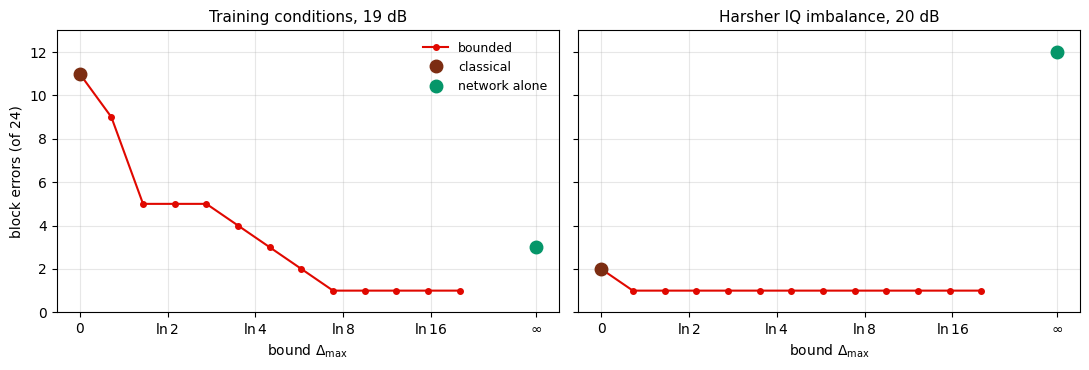

In [7]:
GRID = np.round(np.arange(0, 3.0001, 0.25), 2)
INF_X = 3.6   # where "network alone" is drawn
t0 = time.time()
SWEEP = {name: [int(block_errors(meta, bound(lc, ln, d), bits).sum()) for d in GRID]
         for name, (meta, lc, ln, bits) in SAMPLES.items()}
print(f"decoded {len(GRID)} bounds x {len(SAMPLES)} samples in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, (meta, lc, ln, bits)) in zip(axes, SAMPLES.items()):
    ax.plot(GRID, SWEEP[name], "-o", color=RED, ms=4, label="bounded")
    ax.plot([0], [STORED[name]["0"].sum()], "o", color=BROWN, ms=9, label="classical")
    ax.plot([INF_X], [STORED[name]["unbounded"].sum()], "o", color=GREEN, ms=9, label="network alone")
    ticks = [0, math.log(2), math.log(4), math.log(8), math.log(16), INF_X]
    ax.set_xticks(ticks, ["0", r"$\ln 2$", r"$\ln 4$", r"$\ln 8$", r"$\ln 16$", r"$\infty$"])
    ax.set_title(f"{meta['label']}, {meta['snr_db']:g} dB", fontsize=11)
    ax.set_xlabel(r"bound $\Delta_{\max}$")
    ax.grid(alpha=0.3)
top = max(max(max(SWEEP[n]), max(int(STORED[n][k].sum()) for k in DMAX)) for n in SAMPLES)
axes[0].set_ylim(0, top + 1)   # one scale for both panels, set after both are drawn
axes[0].yaxis.get_major_locator().set_params(integer=True)
axes[0].set_ylabel(f"block errors (of {len(lc)})")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

In [8]:
MY_DMAX = 1.0   # change me
for name, (meta, lc, ln, bits) in SAMPLES.items():
    n_err = block_errors(meta, bound(lc, ln, MY_DMAX), bits).sum()
    print(f"{meta['label']}: Δmax = {MY_DMAX:g} -> {n_err} of {len(lc)} blocks in error")

Training conditions: Δmax = 1 -> 5 of 24 blocks in error


Harsher IQ imbalance: Δmax = 1 -> 1 of 24 blocks in error


## 5. Your own receiver's LLRs

The bound works on any pair of receivers: pass your classical LLRs and your network's LLRs to `bound()`. To decode them with
the decoder above, the arrays must have this slot format's shape, one row per block, with the sign convention printed in
section 1. For another slot format, build a decoder with `SimConfig` and `PdschSim` from `receiver/r1_baseline.py` (see
`build_decoder` in `receiver/ra4_offline_ladder.py` for the settings used here).

As an example, take a network that is badly wrong: the trained network's LLRs with every sign flipped, decoded alone and
through the bound at several settings.

In [9]:
def check_llrs(meta, *arrays):
    "Raise if an array cannot be decoded with this sample's decoder."
    for a in arrays:
        a = np.asarray(a)
        if a.ndim != 2 or a.shape[1] != meta["n_coded_bits"]:
            raise ValueError(f"expected shape (blocks, {meta['n_coded_bits']:,}), got {a.shape}")
        if not np.isfinite(a).all():
            raise ValueError("LLRs must be finite")

meta, lc, ln, bits = SAMPLES["training_snr19"]
my_classical = lc           # e.g. np.load("my_classical_llrs.npy")
my_network = -ln            # e.g. np.load("my_network_llrs.npy"); here: the trained network with its signs flipped
check_llrs(meta, my_classical, my_network)

print("A network with every sign flipped, through the bound:")
for k in ("unbounded", "ln8", "ln4", "ln2", "0"):
    n_err = block_errors(meta, bound(my_classical, my_network, DMAX[k]), bits).sum()
    print(f"   {LABEL[k]:<26}{n_err:>3} of {len(bits)} blocks in error")

A network with every sign flipped, through the bound:


   network alone (Δmax = ∞)   24 of 24 blocks in error


   Δmax = ln 8                24 of 24 blocks in error


   Δmax = ln 4                21 of 24 blocks in error


   Δmax = ln 2                17 of 24 blocks in error


   classical (Δmax = 0)       11 of 24 blocks in error


The bound limits how far each bit can move, not how many blocks fail. A network that is wrong on every bit pushes every bit
the full $\Delta_{\max}$ the wrong way, so blocks the classical receiver decoded with little margin can fail. The smaller
$\Delta_{\max}$, the less any network can move the result away from the classical receiver, and $\Delta_{\max} = 0$ is the
classical receiver whatever the network does. Choosing $\Delta_{\max}$ trades this worst case against the gain in sections 3 and 4.

## What this notebook does not do

- It does not run the channel simulator or the network: the LLRs were computed in advance on the authors' workstation. Running
  the full simulator with the trained network needs a GPU and is a later update.
- A few dozen blocks show the bound at work; they do not measure an error rate. The error rates on the page come from every
  block of three seeds per point.

Please cite the paper: A. Elnashar and M. AlHaj, "A Bounded Neural Receiver with Exact Classical Fallback for 6G cmWave:
Fair-Baseline Evaluation," *IEEE Open Journal of the Communications Society*, 2026.